<a href="https://colab.research.google.com/github/ksrivithya/EGFR-QSAR-Portfolio/blob/main/Chemistry_AI_Verification_Portfolio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chemistry AI Evaluation & Verification Portfolio: Automated Chemical Validity, Stereochemistry & Reaction Auditing with RDKit

**Author:** Chemistry AI & Cheminformatics Portfolio Project  
**Pipeline Architecture:** LLM Output Auditing $\rightarrow$ Syntax & Valence Sanitization (`RDKit`) $\rightarrow$ Canonical SMILES & InChIKey Equivalence $\rightarrow$ Stereochemistry & Chiral Center Verification $\rightarrow$ SMARTS Reaction Rule & Mass-Balance Validation $\rightarrow$ Automated Benchmark Grading Dashboard

---

### Project Objective
Frontier Large Language Models (LLMs) and generative chemistry agents frequently hallucinate chemically invalid SMILES strings, drop stereocenters, or propose unbalanced reaction products. This notebook demonstrates an **automated, deterministic Python/RDKit verification pipeline** designed for **Chemistry AI Evaluation, RLHF Rubric Grading, and Benchmark Auditing**:
1. **Valence & Syntax Auditing:** Programmatically catching hypervalent carbon atoms, unclosed ring closures, and kekulization failures in LLM-generated SMILES.
2. **Canonical & Stereochemical Equivalence:** Resolving non-canonical SMILES strings via `InChIKey` connectivity vs. full stereochemical layers to catch dropped $(R)/(S)$ or $(E)/(Z)$ configurations.
3. **Reaction Product & Functional Group Verification:** Applying SMARTS reaction templates (`rdChemReactions`) and atom-economy/mass-balance checks to grade organic synthesis predictions.

## Step 1: Environment Setup
Install `rdkit`, `pandas`, `matplotlib`, and `seaborn` (runs in ~10 seconds with zero external binary dependencies).

In [1]:
!pip install -q rdkit pandas numpy matplotlib seaborn

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem, Descriptors, rdMolDescriptors, rdChemReactions

# Capture RDKit stderr warnings for diagnostic reporting
RDLogger.DisableLog('rdApp.*')
sns.set_theme(style="whitegrid", palette="deep")
print("Automated Chemical Verification Engine Initialized Successfully!")

Automated Chemical Verification Engine Initialized Successfully!


## Step 2: Automated SMILES Syntax, Valence & Hallucination Auditor
When grading AI-generated molecules, surface-level string matching fails. Our `audit_llm_smiles()` function evaluates:
- **Parse & Valence Check (`Chem.MolFromSmiles`):** Detects impossible valences (e.g., pentavalent carbon `C(C)(C)(C)(C)C`), unclosed rings, or broken aromaticity.
- **Fragment / Salt Check:** Flags disconnected fragments (`.`) when a single pure compound is requested.
- **Exact Molecular Formula & Monoisotopic Mass (`rdMolDescriptors`):** Verifies stoichiometric consistency against reference targets.

In [3]:
def audit_llm_smiles(prompt_target, predicted_smiles, expected_smiles):
    ref_mol = Chem.MolFromSmiles(expected_smiles)
    ref_canonical = Chem.MolToSmiles(ref_mol, canonical=True, isomericSmiles=True)
    ref_inchikey = Chem.MolToInchiKey(ref_mol)
    ref_formula = rdMolDescriptors.CalcMolFormula(ref_mol)

    pred_mol = Chem.MolFromSmiles(predicted_smiles)
    if pred_mol is None:
        return {
            "Target_Compound": prompt_target,
            "LLM_Predicted_SMILES": predicted_smiles,
            "Valid_Valence_Syntax": False,
            "Connectivity_Match": False,
            "Stereochemistry_Match": False,
            "Formula": "INVALID",
            "Automated_Verdict": "FAIL: Invalid Chemical Valence / Syntax Hallucination"
        }

    pred_canonical = Chem.MolToSmiles(pred_mol, canonical=True, isomericSmiles=True)
    pred_inchikey = Chem.MolToInchiKey(pred_mol)
    pred_formula = rdMolDescriptors.CalcMolFormula(pred_mol)

    # InChIKey first 14 characters encode molecular graph connectivity; full 27 chars encode stereochemistry
    connectivity_match = (ref_inchikey[:14] == pred_inchikey[:14])
    stereo_match = (ref_inchikey == pred_inchikey)

    if stereo_match:
        verdict = "PASS: Exact Structure & Stereochemistry Match"
    elif connectivity_match:
        verdict = "PARTIAL: Correct Connectivity, Missing/Wrong Stereochemistry"
    else:
        verdict = "FAIL: Valid Molecule, Wrong Chemical Identity"

    return {
        "Target_Compound": prompt_target,
        "LLM_Predicted_SMILES": predicted_smiles,
        "Valid_Valence_Syntax": True,
        "Connectivity_Match": connectivity_match,
        "Stereochemistry_Match": stereo_match,
        "Formula": pred_formula,
        "Automated_Verdict": verdict
    }

# Simulated LLM Evaluation Benchmark Suite
llm_test_cases = [
    ("Aspirin (Non-canonical valid SMILES)", "O=C(O)c1ccccc1OC(=O)C", "CC(=O)OC1=CC=CC=C1C(=O)O"),
    ("Gefitinib (Exact canonical match)", "COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1", "COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1"),
    ("(S)-Ibuprofen (Dropped chiral center)", "CC(C)Cc1ccc(C(C)C(=O)O)cc1", "CC(C)Cc1ccc([C@@H](C)C(=O)O)cc1"),
    ("Thalidomide (Wrong enantiomer)", "O=C1CC[C@H](N2C(=O)c3ccccc3C2=O)C(=O)N1", "O=C1CC[C@@H](N2C(=O)c3ccccc3C2=O)C(=O)N1"),
    ("Pentavalent Carbon Hallucination", "CC(C)(C)(C)(C)C(=O)O", "CC(C)(C)C(=O)O"),
    ("Broken Aromatic Ring Hallucination", "c1cccc1C(=O)O", "c1ccccc1C(=O)O"),
    ("Caffeine vs. Theobromine Isomer Error", "CN1C=NC2=C1C(=O)NC(=O)N2C", "CN1C=NC2=C1C(=O)N(C(=O)N2C)C")
]

df_audit = pd.DataFrame([audit_llm_smiles(t, p, e) for t, p, e in llm_test_cases])
display(df_audit)

,Target_Compound,LLM_Predicted_SMILES,Valid_Valence_Syntax,Connectivity_Match,Stereochemistry_Match,Formula,Automated_Verdict
0,Aspirin (Non-canonical valid SMILES),O=C(O)c1ccccc1OC(=O)C,True,True,True,C9H8O4,PASS: Exact Structure & Stereochemistry Match
1,Gefitinib (Exact canonical match),COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1,True,True,True,C22H24ClFN4O3,PASS: Exact Structure & Stereochemistry Match
2,(S)-Ibuprofen (Dropped chiral center),CC(C)Cc1ccc(C(C)C(=O)O)cc1,True,True,False,C13H18O2,"PARTIAL: Correct Connectivity, Missing/Wrong S..."
3,Thalidomide (Wrong enantiomer),O=C1CC[C@H](N2C(=O)c3ccccc3C2=O)C(=O)N1,True,True,False,C13H10N2O4,"PARTIAL: Correct Connectivity, Missing/Wrong S..."
4,Pentavalent Carbon Hallucination,CC(C)(C)(C)(C)C(=O)O,False,False,False,INVALID,FAIL: Invalid Chemical Valence / Syntax Halluc...
5,Broken Aromatic Ring Hallucination,c1cccc1C(=O)O,False,False,False,INVALID,FAIL: Invalid Chemical Valence / Syntax Halluc...
6,Caffeine vs. Theobromine Isomer Error,CN1C=NC2=C1C(=O)NC(=O)N2C,True,False,False,C7H8N4O2,"FAIL: Valid Molecule, Wrong Chemical Identity"


## Step 3: Stereochemical & Chiral Center Inspection (`Chem.FindMolChiralCenters`)
In medicinal chemistry and AI evaluation benchmarks, dropping or inverting a single chiral center changes biological activity (e.g., `(R)`- vs. `(S)`-Thalidomide or `(S)`-Ibuprofen). Here we programmatically extract CIP `(R)/(S)` assignments and unassigned stereocenters.

In [4]:
def inspect_stereochemistry(name, smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return {"Molecule": name, "Assigned_Chiral_Centers": "Invalid SMILES", "Unassigned_Stereocenters": None}

    # includeUnassigned=True catches racemic/unspecified stereocenters missed by an AI model
    chiral_centers = Chem.FindMolChiralCenters(mol, includeUnassigned=True)
    assigned = [f"Atom {idx}: ({cip})" for idx, cip in chiral_centers if cip in ("R", "S")]
    unassigned = [f"Atom {idx}: (?)" for idx, cip in chiral_centers if cip == "?"]

    return {
        "Molecule": name,
        "Assigned_Chiral_Centers": ", ".join(assigned) if assigned else "None",
        "Unassigned_Stereocenters": ", ".join(unassigned) if unassigned else "None (Fully Specified)"
    }

stereo_samples = [
    ("(S)-Ibuprofen (Ground Truth)", "CC(C)Cc1ccc([C@@H](C)C(=O)O)cc1"),
    ("LLM Output (Missing Wedge/Dash)", "CC(C)Cc1ccc(C(C)C(=O)O)cc1"),
    ("(R)-Thalidomide", "O=C1CC[C@@H](N2C(=O)c3ccccc3C2=O)C(=O)N1"),
    ("(S)-Thalidomide", "O=C1CC[C@H](N2C(=O)c3ccccc3C2=O)C(=O)N1"),
    ("Osimertinib (Achiral)", "COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1nccc(-c2cn(C)c3ccccc23)n1")
]

df_stereo = pd.DataFrame([inspect_stereochemistry(n, s) for n, s in stereo_samples])
display(df_stereo)

,Molecule,Assigned_Chiral_Centers,Unassigned_Stereocenters
0,(S)-Ibuprofen (Ground Truth),Atom 8: (R),None (Fully Specified)
1,LLM Output (Missing Wedge/Dash),None,Atom 8: (?)
2,(R)-Thalidomide,Atom 4: (R),None (Fully Specified)
3,(S)-Thalidomide,Atom 4: (S),None (Fully Specified)
4,Osimertinib (Achiral),None,None (Fully Specified)


## Step 4: Automated Organic Reaction & Product Verification (`SMARTS` Templates)
When an AI predicts the product of an organic reaction (such as **amide coupling** or **Fischer esterification**), we can verify:
1. Whether the predicted product matches the theoretical **SMARTS reaction transform**.
2. Whether the stoichiometric **heavy-atom mass balance** holds (accounting for condensation byproducts such as $\text{H}_2\text{O}$).

In [5]:
# Define SMARTS reaction template: Carboxylic Acid + Primary/Secondary Amine -> Amide
amide_coupling_rxn = rdChemReactions.ReactionFromSmarts("[C:1](=[O:2])[OH].[N;H2,H1:3]>>[C:1](=[O:2])[N:3]")

acid_smiles = "CC(=O)O"          # Acetic acid
amine_smiles = "Nc1ccc(O)cc1"    # 4-Aminophenol
expected_product = "CC(=O)Nc1ccc(O)cc1"  # Paracetamol (Acetaminophen)

mol_acid = Chem.MolFromSmiles(acid_smiles)
mol_amine = Chem.MolFromSmiles(amine_smiles)

# Run theoretical forward reaction in RDKit
rxn_products = amide_coupling_rxn.RunReactants((mol_acid, mol_amine))
theoretical_prod_mol = rxn_products[0][0]
Chem.SanitizeMol(theoretical_prod_mol)
theoretical_canonical = Chem.MolToSmiles(theoretical_prod_mol, canonical=True)

# Test 3 simulated AI reaction predictions
ai_reaction_submissions = [
    ("Model A (Correct Amide: Paracetamol)", "CC(=O)Nc1ccc(O)cc1"),
    ("Model B (Chemoselectivity Error: Ester instead of Amide)", "CC(=O)Oc1ccc(N)cc1"),
    ("Model C (Missing Dehydration: Uncondensed Adduct)", "CC(O)(O)Nc1ccc(O)cc1")
]

rxn_audit_rows = []
for model_name, pred_smi in ai_reaction_submissions:
    pred_m = Chem.MolFromSmiles(pred_smi)
    pred_can = Chem.MolToSmiles(pred_m, canonical=True)
    matches_rxn = (pred_can == theoretical_canonical)

    # Check heavy atom balance: Reactants (4 + 8 = 12 heavy atoms) - Water (1 O atom) = 11 heavy atoms
    expected_heavy_atoms = mol_acid.GetNumHeavyAtoms() + mol_amine.GetNumHeavyAtoms() - 1
    actual_heavy_atoms = pred_m.GetNumHeavyAtoms()

    rxn_audit_rows.append({
        "Submission": model_name,
        "Predicted_Product_SMILES": pred_can,
        "Expected_Heavy_Atoms": expected_heavy_atoms,
        "Actual_Heavy_Atoms": actual_heavy_atoms,
        "Matches_SMARTS_Transform": matches_rxn,
        "Grading_Decision": "PASS (Valid Amide Coupling Product)" if matches_rxn else "FAIL (Chemoselectivity / Stoichiometry Error)"
    })

df_rxn = pd.DataFrame(rxn_audit_rows)
display(df_rxn)

,Submission,Predicted_Product_SMILES,Expected_Heavy_Atoms,Actual_Heavy_Atoms,Matches_SMARTS_Transform,Grading_Decision
0,Model A (Correct Amide: Paracetamol),CC(=O)Nc1ccc(O)cc1,11,11,True,PASS (Valid Amide Coupling Product)
1,Model B (Chemoselectivity Error: Ester instead...,CC(=O)Oc1ccc(N)cc1,11,11,False,FAIL (Chemoselectivity / Stoichiometry Error)
2,Model C (Missing Dehydration: Uncondensed Adduct),CC(O)(O)Nc1ccc(O)cc1,11,12,False,FAIL (Chemoselectivity / Stoichiometry Error)


## Step 5: Benchmark Error Breakdown Visualization
Visualize the distribution of automated verification outcomes across our LLM evaluation suite—demonstrating why multi-layer RDKit checks (Syntax $\rightarrow$ Connectivity $\rightarrow$ Stereochemistry) are essential for high-precision Chemistry AI grading.

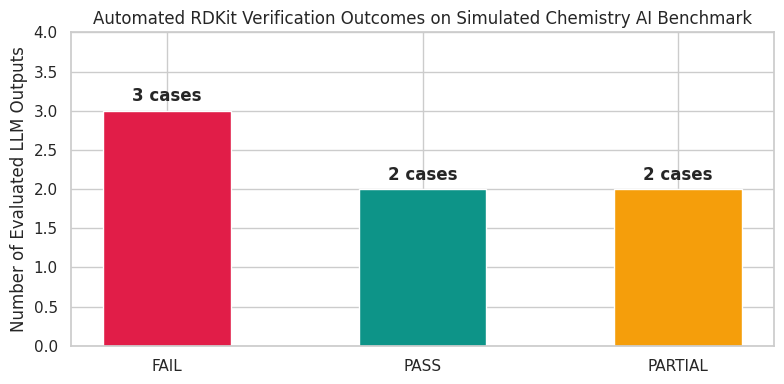

In [6]:
df_audit["Outcome_Category"] = df_audit["Automated_Verdict"].apply(lambda x: x.split(":")[0])
counts = df_audit["Outcome_Category"].value_counts()

plt.figure(figsize=(8, 4))
palette = {"PASS": "#0d9488", "PARTIAL": "#f59e0b", "FAIL": "#e11d48"}
bars = plt.bar(counts.index, counts.values, color=[palette.get(k, "#64748b") for k in counts.index], width=0.5)
plt.ylabel("Number of Evaluated LLM Outputs")
plt.title("Automated RDKit Verification Outcomes on Simulated Chemistry AI Benchmark")
plt.ylim(0, max(counts.values) + 1)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.12, f"{int(yval)} cases", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

### Scientific Takeaways for Chemistry AI Evaluation
- **Beyond String Matching:** Non-canonical SMILES strings (such as `O=C(O)c1ccccc1OC(=O)C` vs. `CC(=O)OC1=CC=CC=C1C(=O)O` for Aspirin) look completely different as raw text, yet `InChIKey` canonicalization confirms 100% structural equivalence.
- **Catching Subtle Stereochemical Drops:** Separating the 14-character `InChIKey` connectivity layer from the full 27-character stereochemical layer allows automated graders to distinguish a totally wrong molecule from a partially correct response that omitted an `(R)/(S)` chiral center.
- **Deterministic Guardrails for AI Training:** Combining domain expertise in organic reaction mechanisms with `rdChemReactions` SMARTS rules provides scalable, hallucination-free ground truth for RLHF rubric design and benchmark verification.